In [1]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations
import re

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

polars.config.Config

In [2]:
#file_path = Path('../outputs/LLM/glint/risultati_llm_20261115_193713.csv')
# file_path = Path('../outputs/LLM/glint/risultati_llm_20261114_162646.csv')
file_path = Path('../outputs/LLM/feret/risultati_llm_20261121_121537.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The face shows closed eyes with a non-neutral expression, cluttered background, uneven lighting, and a small head, despite the passport-style photo's typical space requirements.""",24,0.17,100,35
"""LFM2-1.2B""","""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""The photo features eyes half-closed, uneven background, and harsh lighting on the face, but the subject's face is well-lit and proportionate to the frame.""",24,0.12,95,35
"""LFM2-1.2B""","""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""The face shows closed eyes with a non-neutral expression, uneven lighting, and a slightly small head, lacking a head covering and improper framing space.""",24,0.11,101,30
"""LFM2-1.2B""","""00552_940519_ql.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly non-neutral expression; head slightly small in the frame; slightly improper space above the head Good aspects: eyes open; no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The face photo shows a slightly non-neutral expression with eyes open, eyes well exposed, and a uniform background, despite a small head and minor lighting issues. The subject's expression and lighting are ideal, with proper space below the face.""",39,0.16,94,48
"""LFM2-1.2B""","""00505_940519_ql.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly non-neutral expression; head slightly small in the frame Good aspects: eyes open; no head covering; uniform background; even lighting on the face; well exposed image; proper space above the head; proper space below the face""","""The face photo shows a subject with slightly open eyes and a neutral expression, head just barely fitting the frame, with even lighting and a uniform background. The image is well-exposed, properly spaced above and below the head.""",38,0.15,93,46


In [3]:
models = {k[0]: v for k, v in df.partition_by('modello', as_dict=True).items()}

In [4]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','risposta', 'tempo_s', 'num_parole'].head(5))

--- LFM2-1.2B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The face shows closed eyes with a non-neutral expression, cluttered background, uneven lighting, and a small head, despite the passport-style photo's typical space requirements.""",0.17,24
"""00170_931230_pl.png""","""The photo features eyes half-closed, uneven background, and harsh lighting on the face, but the subject's face is well-lit and proportionate to the frame.""",0.12,24
"""00445_940422_pl.png""","""The face shows closed eyes with a non-neutral expression, uneven lighting, and a slightly small head, lacking a head covering and improper framing space.""",0.11,24
"""00552_940519_ql.png""","""The face photo shows a slightly non-neutral expression with eyes open, eyes well exposed, and a uniform background, despite a small head and minor lighting issues. The subject's expression and lighting are ideal, with proper space below the face.""",0.16,39
"""00505_940519_ql.png""","""The face photo shows a subject with slightly open eyes and a neutral expression, head just barely fitting the frame, with even lighting and a uniform background. The image is well-exposed, properly spaced above and below the head.""",0.15,38


--- Gemma-3-1B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The photo features closed eyes and a subdued expression, with a slightly uneven lighting setup. The face is noticeably cluttered and lacks a neutral appearance, creating a sense of quietness.""",0.24,30
"""00170_931230_pl.png""","""Here’s a description: The photo features a face with partially closed eyes and uneven lighting, creating a slightly shadowed appearance. The background is noticeably dark, and the head appears too small within the frame.""",0.23,34
"""00445_940422_pl.png""","""Here’s a description: The image features a face with closed eyes and a largely obscured expression, displaying a stark and uneven lighting condition. The face is noticeably small in the frame, with a dark background and an unbalanced space above it.""",0.26,41
"""00552_940519_ql.png""","""Here’s a description: The photograph features a face with a subtle, slightly melancholic expression. The head is smaller than the frame, and there’s a slight imbalance in the space above the face.""",0.23,32
"""00505_940519_ql.png""","""Here’s a description: The photograph features a face with a subtle, slightly melancholic expression. The head is relatively small within the frame, and the lighting is even, creating a calm and natural feel.""",0.23,33


--- Qwen3-4B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The photo has a clear, well-exposed image with proper space above and below the face. It lacks head covering, but has slightly uneven lighting and a cluttered background.""",0.37,28
"""00170_931230_pl.png""","""The face is slightly uneven in lighting and has a strongly uneven background. Proper space is above the head and below the face, with no head covering.""",0.31,27
"""00445_940422_pl.png""","""The photo has a clearly non-neutral expression and shows no head covering. The background is uniform, but the head is slightly small in the frame and there is improper space above the head.""",0.37,33
"""00552_940519_ql.png""","""The photo has eyes open, no head covering, uniform background, and even lighting on the face. It is well exposed with proper space below the face, though the head is slightly small in the frame and the expression is slightly non-neutral.""",0.47,41
"""00505_940519_ql.png""","""The face is slightly tilted with eyes open, no head covering, and uniform background. Lighting is even on the face, the image is well exposed, and there is proper space above and below the head.""",0.4,35


... (4 outputs left out)

--- Qwen3-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The subject has eyes closed or mostly closed and a clearly non-neutral expression. The background is cluttered and non-uniform, with slightly uneven lighting and the head appearing too small in the frame.""",0.65,32
"""00170_931230_pl.png""","""The face photo shows eyes partly closed with strongly uneven lighting on the face. The background is slightly uneven, and the image is clearly too dark or too bright, with the head appearing too small in the frame.""",0.65,38
"""00445_940422_pl.png""","""The subject has eyes closed or mostly closed and a clearly non-neutral expression. The face shows strongly uneven lighting, with the image too dark or too bright. The head appears slightly small in the frame with improper space above it, but there is no head covering and the background is uniform with proper space below the face.""",0.95,57
"""00552_940519_ql.png""","""The passport-style face photo shows a slightly non-neutral expression and a head that is slightly small in the frame. The head has slightly improper space above it, but the eyes are open, there is no head covering, the background is uniform, lighting is even, the image is well exposed, and there is proper space below the face.""",1.0,57
"""00505_940519_ql.png""","""The passport-style face photo shows a slightly non-neutral expression and a head that is slightly small in the frame. It features open eyes, no head covering, a uniform background, even lighting on the face, proper spacing above and below the face, and is well exposed.""",0.81,45


--- Llama-3.1-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The passport-style face photo shows a person with a clearly non-neutral expression, eyes mostly closed, and a cluttered background. The image is well-exposed, but has uneven lighting and the head is too small in the frame.""",0.82,36
"""00170_931230_pl.png""","""The passport-style face photo shows a person with eyes partly closed, set against a slightly uneven background with strongly uneven lighting on the face. The image is either too dark or too bright, with the head appearing too small in the frame.""",0.73,42
"""00445_940422_pl.png""","""The passport-style face photo shows a person with a non-neutral expression and eyes mostly closed, against a uniform background. The image is affected by uneven lighting, resulting in an overly dark or bright appearance.""",0.64,34
"""00552_940519_ql.png""","""The face photo shows a person with their eyes open, a uniform background, and even lighting on their face. However, the image has some issues, including a slightly non-neutral expression and improper space above the head.""",0.67,36
"""00505_940519_ql.png""","""The face photo shows a person with their eyes open, looking directly at the camera, and a neutral background with even lighting on their face. The image is well-exposed, with proper space above and below the face, but the expression is slightly non-neutral and the head is slightly small in the frame.""",0.92,52


In [5]:
target = ['num_parole', 'tempo_s', 'prompt_tokens', 'completion_tokens']

for model, df_sub in models.items():
    print(f"=== Statistiche per il modello: {model} ===")
    
    display(df_sub[target].describe())
    print("\n")

=== Statistiche per il modello: LFM2-1.2B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",31.471131,0.134381,94.092622,40.363272
"""std""",6.468737,0.024388,4.324589,8.245892
"""min""",16.0,0.08,84.0,24.0
"""25%""",27.0,0.12,91.0,35.0
"""50%""",31.0,0.13,94.0,40.0
"""75%""",35.0,0.15,97.0,45.0
"""max""",102.0,0.41,108.0,133.0




=== Statistiche per il modello: Gemma-3-1B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",35.016239,0.22902,93.878709,44.96652
"""std""",3.914816,0.022601,4.057923,4.947639
"""min""",23.0,0.16,84.0,29.0
"""25%""",33.0,0.22,91.0,42.0
"""50%""",35.0,0.23,94.0,45.0
"""75%""",37.0,0.24,96.0,48.0
"""max""",51.0,0.31,107.0,62.0




=== Statistiche per il modello: Qwen3-4B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",34.913392,0.392668,94.84162,41.65397
"""std""",5.524915,0.058924,4.068712,6.663633
"""min""",21.0,0.23,85.0,24.0
"""25%""",31.0,0.35,92.0,37.0
"""50%""",35.0,0.39,95.0,42.0
"""75%""",38.0,0.43,98.0,46.0
"""max""",57.0,0.63,108.0,69.0


... (4 outputs left out)



=== Statistiche per il modello: Qwen3-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",43.606856,0.820309,94.84162,52.338212
"""std""",8.92569,0.161718,4.068712,10.588938
"""min""",20.0,0.39,85.0,24.0
"""25%""",37.0,0.7,92.0,44.0
"""50%""",45.0,0.84,95.0,54.0
"""75%""",51.0,0.94,98.0,61.0
"""max""",66.0,1.21,108.0,79.0




=== Statistiche per il modello: Llama-3.1-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",40.415798,0.747757,116.84162,49.140938
"""std""",4.66821,0.12798,4.068712,5.338697
"""min""",27.0,0.5,107.0,33.0
"""25%""",37.0,0.69,114.0,46.0
"""50%""",40.0,0.74,117.0,49.0
"""75%""",43.0,0.79,120.0,52.0
"""max""",60.0,2.9,130.0,70.0


In [6]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','prompt','risposta'].head(3))

--- LFM2-1.2B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The face shows closed eyes with a non-neutral expression, cluttered background, uneven lighting, and a small head, despite the passport-style photo's typical space requirements."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""The photo features eyes half-closed, uneven background, and harsh lighting on the face, but the subject's face is well-lit and proportionate to the frame."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""The face shows closed eyes with a non-neutral expression, uneven lighting, and a slightly small head, lacking a head covering and improper framing space."""


--- Gemma-3-1B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The photo features closed eyes and a subdued expression, with a slightly uneven lighting setup. The face is noticeably cluttered and lacks a neutral appearance, creating a sense of quietness."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""Here’s a description: The photo features a face with partially closed eyes and uneven lighting, creating a slightly shadowed appearance. The background is noticeably dark, and the head appears too small within the frame."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""Here’s a description: The image features a face with closed eyes and a largely obscured expression, displaying a stark and uneven lighting condition. The face is noticeably small in the frame, with a dark background and an unbalanced space above it."""


--- Qwen3-4B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The photo has a clear, well-exposed image with proper space above and below the face. It lacks head covering, but has slightly uneven lighting and a cluttered background."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""The face is slightly uneven in lighting and has a strongly uneven background. Proper space is above the head and below the face, with no head covering."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""The photo has a clearly non-neutral expression and shows no head covering. The background is uniform, but the head is slightly small in the frame and there is improper space above the head."""


... (4 outputs left out)

--- Qwen3-8B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The subject has eyes closed or mostly closed and a clearly non-neutral expression. The background is cluttered and non-uniform, with slightly uneven lighting and the head appearing too small in the frame."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""The face photo shows eyes partly closed with strongly uneven lighting on the face. The background is slightly uneven, and the image is clearly too dark or too bright, with the head appearing too small in the frame."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""The subject has eyes closed or mostly closed and a clearly non-neutral expression. The face shows strongly uneven lighting, with the image too dark or too bright. The head appears slightly small in the frame with improper space above it, but there is no head covering and the background is uniform with proper space below the face."""


--- Llama-3.1-8B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; cluttered, non-uniform background; slightly uneven lighting; head too small in the frame Good aspects: no head covering; well exposed image; proper space above the head; proper space below the face""","""The passport-style face photo shows a person with a clearly non-neutral expression, eyes mostly closed, and a cluttered background. The image is well-exposed, but has uneven lighting and the head is too small in the frame."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face""","""The passport-style face photo shows a person with eyes partly closed, set against a slightly uneven background with strongly uneven lighting on the face. The image is either too dark or too bright, with the head appearing too small in the frame."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; strongly uneven lighting on the face; image clearly too dark or too bright; head slightly small in the frame; improper space above the head Good aspects: no head covering; uniform background; proper space below the face""","""The passport-style face photo shows a person with a non-neutral expression and eyes mostly closed, against a uniform background. The image is affected by uneven lighting, resulting in an overly dark or bright appearance."""


### Confronto fra modelli: similarità fra le risposte

In [7]:
embedder_name = 'paraphrase-multilingual-MiniLM-L12-v2'
emb_model = SentenceTransformer(embedder_name)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (3 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [8]:
embeddings = {
    nome: emb_model.encode(
        d["risposta"].to_list(),  
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    for nome, d in models.items()
}

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

In [9]:
models_name = list(embeddings)

similarities = {
    (a,b): (embeddings[a] * embeddings[b]).sum(axis=1)
    for a,b in combinations(models_name,2)
}

M = np.eye(len(models_name))
for i,a in enumerate(models_name):
    for j,b in enumerate(models_name):
        if i < j:
            M[i, j] = M[j, i] = similarities[(a, b)].mean()

mat = pl.DataFrame(M,schema=models_name).with_columns(pl.Series('modello',models_name))

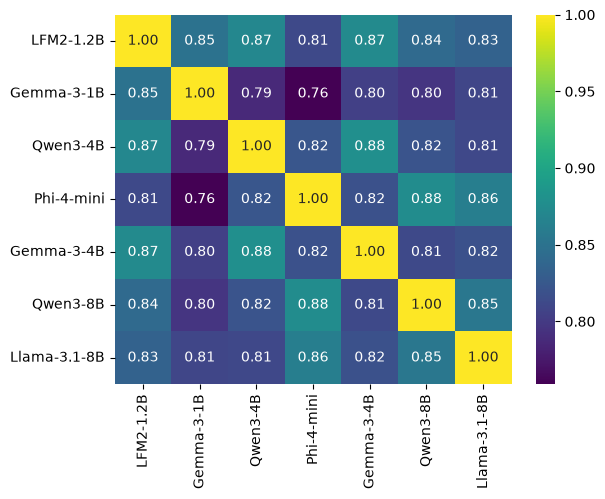

In [10]:
sns.heatmap(M, xticklabels=models_name, yticklabels=models_name, annot=True, fmt=".2f", cmap="viridis")
plt.show()

In [11]:
righe = []
for (a, b), s in similarities.items():
    righe.append({
        "A": a, "B": b,
        "media": s.mean(),
        "p5": np.percentile(s, 5),
        "mediana": np.median(s),
        "p95": np.percentile(s, 95),
    })
confronto = pl.DataFrame(righe).sort("media", descending=True)

In [12]:
confronto

A,B,media,p5,mediana,p95
str,str,f64,f64,f64,f64
"""Qwen3-4B""","""Gemma-3-4B""",0.87842,0.795964,0.8857,0.943523
"""Phi-4-mini""","""Qwen3-8B""",0.875321,0.720365,0.90342,0.962446
"""LFM2-1.2B""","""Gemma-3-4B""",0.873178,0.783565,0.878815,0.938102
"""LFM2-1.2B""","""Qwen3-4B""",0.870182,0.776752,0.878463,0.938843
"""Phi-4-mini""","""Llama-3.1-8B""",0.861218,0.746809,0.875857,0.94176
"""Qwen3-8B""","""Llama-3.1-8B""",0.854839,0.670602,0.867163,0.963016
"""LFM2-1.2B""","""Gemma-3-1B""",0.849761,0.747958,0.857929,0.921478
"""LFM2-1.2B""","""Qwen3-8B""",0.8417,0.758968,0.842818,0.925051
"""LFM2-1.2B""","""Llama-3.1-8B""",0.834028,0.746422,0.828729,0.936625


In [21]:
def get_prompt_features(p: str):
    issues, good = [], []

    m_issues = re.search(r"Issues:\s*(.*?)(?:\n|$)", p)
    m_good = re.search(r"Good aspects:\s*(.*?)(?:\n|$)", p)

    if m_issues:
        issues = [x.strip() for x in m_issues.group(1).split(";") if x.strip()]
    if m_good:
        good = [x.strip() for x in m_good.group(1).split(";") if x.strip()]

    return issues, good

In [ ]:
for nome, d in list(models.items()):
    liste = [get_prompt_features(p) for p in d["prompt"].to_list()]
    models[nome] = d.with_columns(
        pl.Series("issues", [l[0] for l in liste], dtype=pl.List(pl.String)),
        pl.Series("good",   [l[1] for l in liste], dtype=pl.List(pl.String)),
    )

from transformers import pipeline

nli = pipeline("text-classification",
               model="cross-encoder/nli-deberta-v3-small", device=-1)

def valuta_modello(d, files):
    d = d.filter(pl.col("file").is_in(files))
    righe, coppie = [], []
    for r in d.iter_rows(named=True):
        for tipo, fatti in (("issue", r["issues"]), ("good", r["good"])):
            for f in fatti:
                righe.append((r["file"], tipo, f))
                coppie.append({"text": r["risposta"],
                               "text_pair": f"The photo shows {f}."})
    out = nli(coppie, batch_size=32, truncation=True)
    return pl.DataFrame({
        "file":  [x[0] for x in righe],
        "tipo":  [x[1] for x in righe],
        "fatto": [x[2] for x in righe],
        "label": [o["label"].lower() for o in out],
    })

files = df["file"].unique(maintain_order=True).sample(300, seed=0).to_list()
risultati = {nome: valuta_modello(d, files) for nome, d in models.items()}

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

In [15]:
tab = []
for nome, r in risultati.items():
    iss = r.filter(pl.col("tipo") == "issue")
    tab.append({
        "modello": nome,
        "recall_difetti": (iss["label"] == "entailment").mean(),
        "difetti_omessi": (iss["label"] == "neutral").mean(),
        "contraddizioni": (r["label"] == "contradiction").mean(),
    })
pl.DataFrame(tab).sort("recall_difetti", descending=True)

r = risultati["Phi-4-mini"]
r.filter((pl.col("tipo") == "issue") & (pl.col("label") != "entailment")).sample(20, seed=1)

file,tipo,fatto,label
str,str,str,str
"""00440_940422_pl.png""","""issue""","""image clearly too dark or too bright""","""contradiction"""
"""00538_940519_fb_a.png""","""issue""","""image slightly too dark or bright""","""neutral"""
"""00521_940519_hr.png""","""issue""","""strongly uneven lighting on the face""","""contradiction"""
"""00203_940128_fb.png""","""issue""","""improper space below the face""","""contradiction"""
"""00428_940422_pl.png""","""issue""","""image clearly too dark or too bright""","""contradiction"""
"""00424_940422_fa.png""","""issue""","""image clearly too dark or too bright""","""neutral"""
"""00439_940422_pl.png""","""issue""","""eyes partly closed""","""contradiction"""
"""00115_931230_pl.png""","""issue""","""improper space above the head""","""neutral"""
"""00502_940519_pr.png""","""issue""","""improper space below the face""","""contradiction"""


In [16]:
lungo = pl.concat([
    r.select("file", "tipo", "fatto", "label")
     .with_columns(modello=pl.lit(nome))
    for nome, r in risultati.items()
]).with_columns(
    contraddizione=(pl.col("label") == "contradiction")
)

tabella = (
    lungo.pivot(
        on="modello",
        index=["tipo", "file", "fatto"],
        values="contraddizione",
        aggregate_function="first",
    )
    .sort("tipo", "file")
)
tabella.head(10)

tipo,file,fatto,LFM2-1.2B,Gemma-3-1B,Qwen3-4B,Phi-4-mini,Gemma-3-4B,Qwen3-8B,Llama-3.1-8B
str,str,str,bool,bool,bool,bool,bool,bool,bool
"""good""","""00002_930831_hl.png""","""well exposed image""",true,false,false,false,false,false,false
"""good""","""00002_930831_hl.png""","""proper space below the face""",true,true,false,false,false,false,false
"""good""","""00002_930831_hl.png""","""proper space above the head""",true,true,false,false,false,false,false
"""good""","""00002_930831_hl.png""","""no head covering""",true,true,false,false,false,false,false
"""good""","""00002_930831_hl.png""","""eyes open""",true,false,false,false,false,false,false
"""good""","""00002_931230_fb.png""","""proper space above the head""",false,true,false,false,false,false,false
"""good""","""00002_931230_fb.png""","""uniform background""",false,true,false,false,false,true,false
"""good""","""00002_931230_fb.png""","""eyes open""",false,true,false,false,false,false,false
"""good""","""00002_931230_fb.png""","""proper space below the face""",false,true,false,false,false,false,false


In [17]:
# lungo = pl.concat([
#     r.with_columns(modello=pl.lit(nome))
#     for nome, r in risultati.items()
# ])

# # 2) aggiungi la risposta del LLM, altrimenti non puoi annotare
# risposte = pl.concat([
#     d.select("file", "risposta").with_columns(modello=pl.lit(nome))
#     for nome, d in models.items()
# ])
# lungo = lungo.join(risposte, on=["modello", "file"], how="left")

# # 3) campione stratificato per (tipo, label): max 17 righe per gruppo -> circa 100
# campione = (
#     lungo.group_by("tipo", "label", maintain_order=True)
#          .map_groups(lambda g: g.sample(min(17, g.height), seed=0))
#          .select("modello", "file", "tipo", "fatto", "risposta", "label")
#          .with_columns(label_umana=pl.lit(None, dtype=pl.String))
# )
# campione.write_csv("../outputs/validazione_nli.csv")
# print(campione.height)

In [18]:
tabella = pl.DataFrame(tab).sort("recall_difetti", descending=True)
tabella

modello,recall_difetti,difetti_omessi,contraddizioni
str,f64,f64,f64
"""Qwen3-8B""",0.8,0.046288,0.220971
"""Gemma-3-1B""",0.783406,0.095197,0.337476
"""Phi-4-mini""",0.704803,0.179039,0.16233
"""LFM2-1.2B""",0.68821,0.139738,0.240777
"""Llama-3.1-8B""",0.655895,0.256769,0.130097
"""Qwen3-4B""",0.547598,0.289083,0.113786
"""Gemma-3-4B""",0.512664,0.324891,0.114175


### Controllo per ogni modello delle feature giuste e sbagliate in base al prompt

In [19]:
tab = []

for nome, r in risultati.items():
    issues = r.filter(pl.col("tipo") == "issue")
    good = r.filter(pl.col("tipo") == "good")

    tab.append({
        "modello": nome,
        "recall_difetti": (issues["label"] == "entailment").mean(),
        "recall_aspetti_positivi": (good["label"] == "entailment").mean(),
        "fatti_contraddetti": (r["label"] == "contradiction").mean(),
        "fatti_non_citati": (r["label"] == "neutral").mean()
    })

pl.DataFrame(tab).sort("recall_difetti", descending=True)

modello,recall_difetti,recall_aspetti_positivi,fatti_contraddetti,fatti_non_citati
str,f64,f64,f64,f64
"""Qwen3-8B""",0.8,0.707692,0.220971,0.030291
"""Gemma-3-1B""",0.783406,0.401399,0.337476,0.091262
"""Phi-4-mini""",0.704803,0.748951,0.16233,0.10835
"""LFM2-1.2B""",0.68821,0.679021,0.240777,0.076117
"""Llama-3.1-8B""",0.655895,0.751748,0.130097,0.160777
"""Qwen3-4B""",0.547598,0.877622,0.113786,0.15534
"""Gemma-3-4B""",0.512664,0.867832,0.114175,0.175922


In [20]:
import polars as pl

# Pulisce le etichette
val = (
    validazione
    .with_columns(
        pl.col("label")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase(),

        pl.col("label_umana")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase()
          .replace({"neurtal": "neutral"}),
    )
    .filter(
        pl.col("label_umana").is_not_null()
        & (pl.col("label_umana") != "")
    )
)

# Accordo percentuale per modello
accordo_modelli = (
    val
    .group_by("modello")
    .agg(
        pl.len().alias("righe_annotate"),
        (pl.col("label") == pl.col("label_umana"))
          .mean()
          .alias("accordo"),
    )
    .with_columns(
        (pl.col("accordo") * 100).round(1).alias("accordo_percentuale")
    )
    .sort("accordo", descending=False)
)

display(accordo_modelli)

# Matrice di confusione per ciascun modello
for modello in val["modello"].unique().sort().to_list():
    print(f"\nModello: {modello}")

    matrice = (
        val
        .filter(pl.col("modello") == modello)
        .group_by(["label_umana", "label"])
        .len()
        .pivot(on="label", index="label_umana", values="len")
        .fill_null(0)
        .sort("label_umana")
    )

    display(matrice)

NameError: name 'validazione' is not defined

In [ ]:
import base64, html, io
from pathlib import Path

import polars as pl
from PIL import Image
from IPython.display import HTML, display


def mostra_tabella(df, shards_dir, cols=None, n=5, files=None, seed=0, width=110, file_col="file"):
    """Una riga per immagine: miniatura + le colonne del DataFrame.
    df         : DataFrame con una colonna 'file' (nome dell'immagine) e le altre colonne da mostrare
    shards_dir : cartella che contiene shard_00000, shard_00001, ...
    cols       : colonne da mostrare (default: tutte tranne 'file' e 'prompt')"""
    index = {p.name: p for p in Path(shards_dir).expanduser().glob("shard_*/*")
             if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}}

    if files is None:
        tutti = df[file_col].unique(maintain_order=True)
        files = tutti.sample(min(n, len(tutti)), seed=seed).to_list()
    cols = cols or [c for c in df.columns if c not in (file_col, "prompt")]
    sub = {r[file_col]: r for r in df.filter(pl.col(file_col).is_in(files)).iter_rows(named=True)}

    def miniatura(name):
        if name not in index:
            return "<i>immagine non trovata</i>"
        im = Image.open(index[name]).convert("RGB")
        im.thumbnail((width * 2, width * 3))
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=80)
        return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{width}">'

    def testo(v):
        if v is None:
            return "-"
        return html.escape("; ".join(map(str, v)) if isinstance(v, list) else str(v))

    righe = []
    for f in files:
        r = sub.get(f, {})
        nome = Path(f).name
        celle = [f"<td>{miniatura(nome)}<br><small>{html.escape(nome)}</small></td>"]
        celle += [f"<td>{testo(r.get(c))}</td>" for c in cols]
        righe.append("<tr>" + "".join(celle) + "</tr>")

    css = ("<style>.tm{border-collapse:collapse;font-size:13px}.tm td,.tm th{border:1px solid #ccc;"
           "padding:6px;vertical-align:top;max-width:260px;word-wrap:break-word;text-align:left}"
           ".tm th{background:#f2f2f2}</style>")
    intest = "".join(f"<th>{html.escape(str(c))}</th>" for c in cols)
    display(HTML(f"{css}<table class='tm'><tr><th>immagine</th>{intest}</tr>" + "".join(righe) + "</table>"))

In [ ]:
mostra_tabella(df, "~/prove/feret_all/images", n=15)    